# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Intifada Afkar Lazain Muhammad | 5054251029|

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

torch.manual_seed(42)
np.random.seed(42)
sns.set_style("whitegrid")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

train_df = pd.read_csv("/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_train.csv")
test_df = pd.read_csv("/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_test.csv")
print("Ukuran train:", train_df.shape)
print("Ukuran test :", test_df.shape)

Ukuran train: (60000, 785)
Ukuran test : (10000, 785)


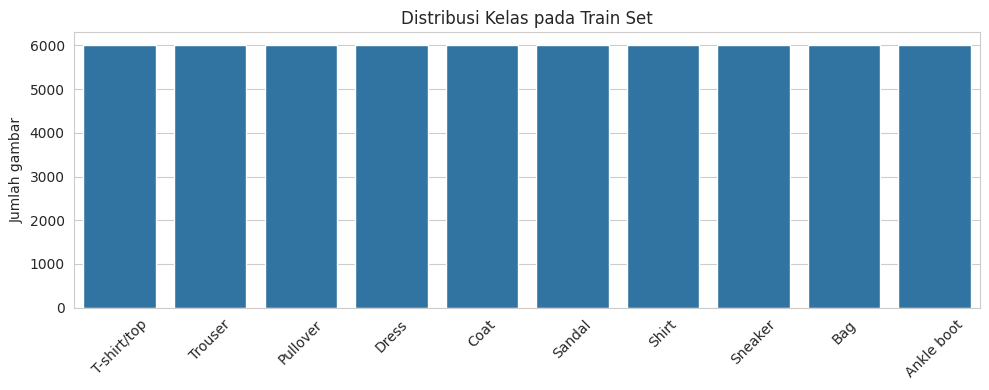

label
T-shirt/top    6000
Trouser        6000
Pullover       6000
Dress          6000
Coat           6000
Sandal         6000
Shirt          6000
Sneaker        6000
Bag            6000
Ankle boot     6000
Name: count, dtype: int64


In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
label_map = {i: n for i, n in enumerate(class_names)}

counts = train_df["label"].value_counts().sort_index()
plt.figure(figsize=(10, 4))
sns.barplot(x=[label_map[i] for i in counts.index], y=counts.values)
plt.xticks(rotation=45)
plt.ylabel("Jumlah gambar")
plt.title("Distribusi Kelas pada Train Set")
plt.tight_layout()
plt.show()
print(counts.rename(index=label_map))

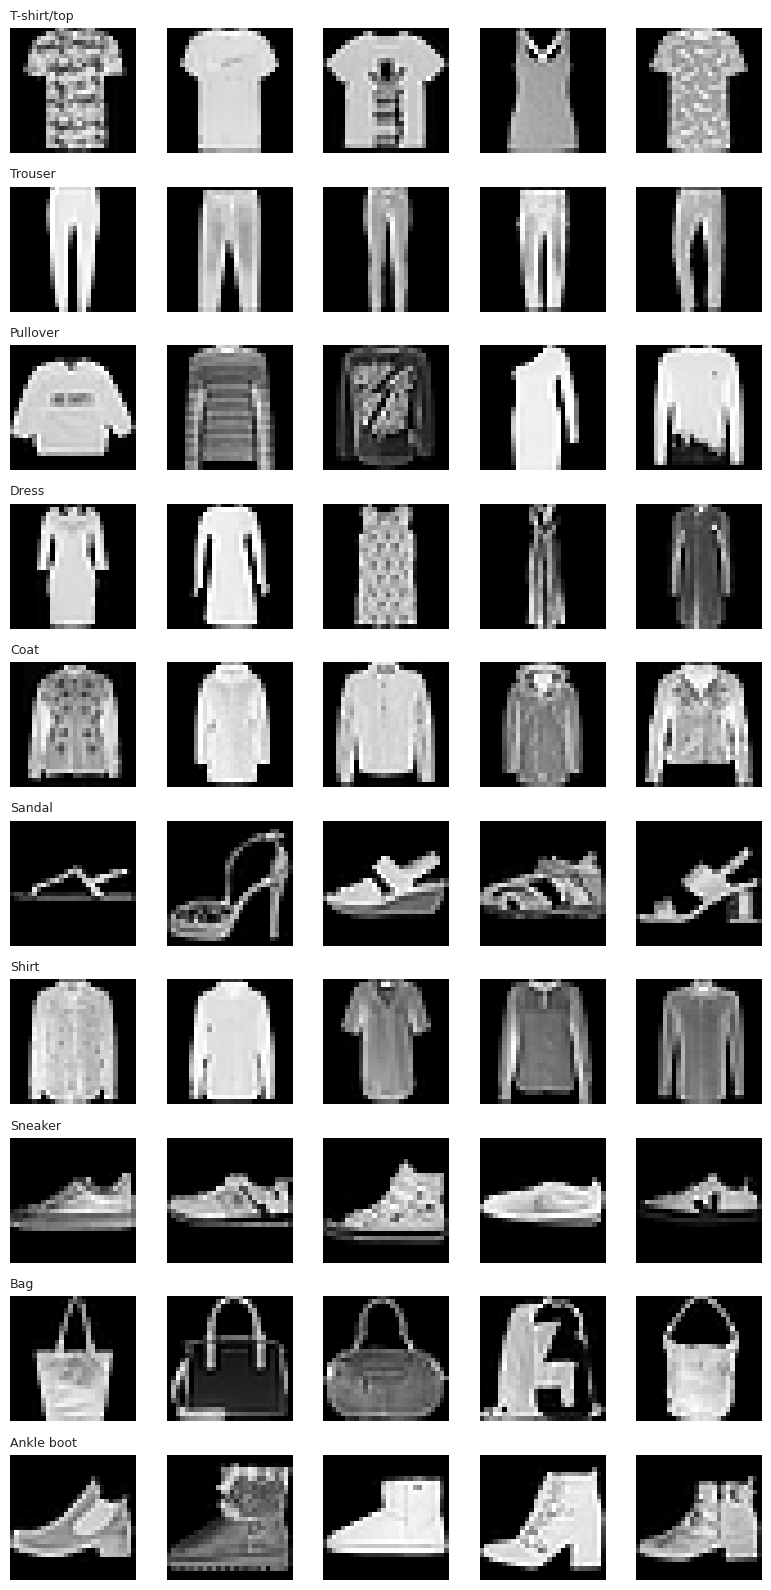

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

imgs_all = train_df.drop(columns="label").values.reshape(-1, 28, 28)
labels_all = train_df["label"].values

fig, axes = plt.subplots(10, 5, figsize=(8, 16))
for c in range(10):
    idx = np.where(labels_all == c)[0][:5]
    for j, i in enumerate(idx):
        axes[c, j].imshow(imgs_all[i], cmap="gray")
        axes[c, j].axis("off")
        if j == 0:
            axes[c, j].set_title(class_names[c], fontsize=9, loc="left")
plt.tight_layout()
plt.show()
# Kelas yang mirip secara visual: T-shirt/top, Shirt, Pullover, dan Coat;
# serta Sandal, Sneaker, dan Ankle boot.

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

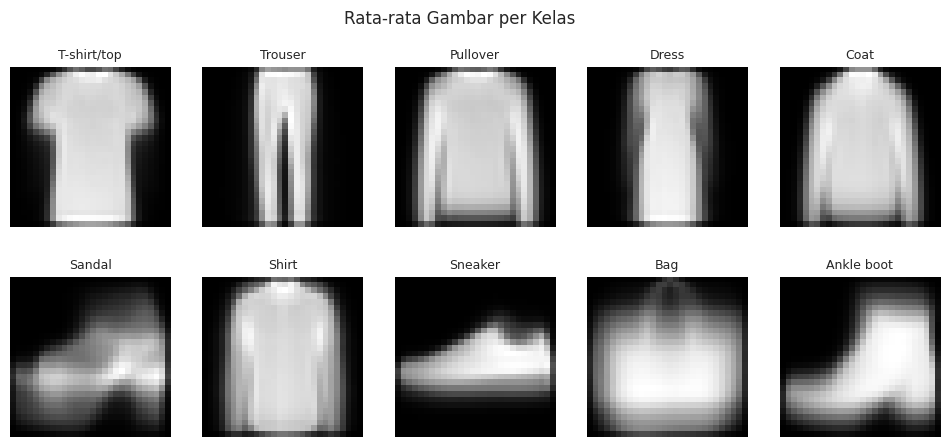

Rata-rata intensitas piksel per kelas:
T-shirt/top    82.9
Trouser        56.7
Pullover       95.7
Dress          66.2
Coat           98.2
Sandal         34.9
Shirt          85.1
Sneaker        42.8
Bag            90.0
Ankle boot     77.0
dtype: float64
Missing value train: 0


In [5]:
# EDA tambahan: rata-rata gambar per kelas dan statistik intensitas piksel
mean_imgs = [imgs_all[labels_all == c].mean(axis=0) for c in range(10)]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(mean_imgs[c], cmap="gray")
    ax.set_title(class_names[c], fontsize=9)
    ax.axis("off")
plt.suptitle("Rata-rata Gambar per Kelas")
plt.show()

print("Rata-rata intensitas piksel per kelas:")
print(pd.Series({class_names[c]: imgs_all[labels_all == c].mean() for c in range(10)}).round(1))
print("Missing value train:", int(train_df.isnull().sum().sum()))

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [6]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

X_train_full = train_df.drop(columns="label").values
y_train_full = train_df["label"].values
X_test_raw = test_df.drop(columns="label").values
y_test_raw = test_df["label"].values
print(X_train_full.shape, y_train_full.shape, X_test_raw.shape, y_test_raw.shape)

(60000, 784) (60000,) (10000, 784) (10000,)


In [7]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_train_full = X_train_full.astype("float32") / 255.0
X_test_raw = X_test_raw.astype("float32") / 255.0
print("Rentang piksel:", X_train_full.min(), "-", X_train_full.max())

Rentang piksel: 0.0 - 1.0


In [8]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.10, stratify=y_train_full, random_state=42)
X_test, y_test = X_test_raw, y_test_raw
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)

Train: (54000, 784) | Val: (6000, 784) | Test: (10000, 784)


In [9]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).

def make_tensors(X, y):
    X_t = torch.tensor(X, dtype=torch.float32).view(-1, 1, 28, 28)
    y_t = torch.tensor(y, dtype=torch.long)
    return X_t, y_t

X_train_t, y_train_t = make_tensors(X_train, y_train)
X_val_t, y_val_t = make_tensors(X_val, y_val)
X_test_t, y_test_t = make_tensors(X_test, y_test)

BATCH_SIZE = 128
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE, shuffle=False)
print(X_train_t.shape, y_train_t.dtype)

torch.Size([54000, 1, 28, 28]) torch.int64


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [10]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).

def count_params(model):
    return sum(p.numel() for p in model.parameters())

class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
ann_model = ANN().to(device)
print(ann_model)
print("Jumlah parameter:", count_params(ann_model))

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 235146


In [11]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total_loss += criterion(out, yb).item() * xb.size(0)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correct / n

def train_model(model, criterion, optimizer, epochs, verbose_every=5):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        tr_loss, tr_acc = evaluate(model, train_loader, criterion)
        va_loss, va_acc = evaluate(model, val_loader, criterion)
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)

        if (epoch + 1) % verbose_every == 0 or epoch == 0:
            print(f"Epoch {epoch+1:2d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} "
                  f"| val loss {va_loss:.4f} acc {va_acc:.4f}")
    return history

LR = 1e-3
EPOCHS = 15

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(ann_model.parameters(), lr=LR)
history_ann = train_model(ann_model, criterion, optimizer, EPOCHS)

Epoch  1/15 | train loss 0.4335 acc 0.8442 | val loss 0.4440 acc 0.8403
Epoch  5/15 | train loss 0.2842 acc 0.8971 | val loss 0.3331 acc 0.8817
Epoch 10/15 | train loss 0.2526 acc 0.9045 | val loss 0.3390 acc 0.8760
Epoch 15/15 | train loss 0.1798 acc 0.9331 | val loss 0.3071 acc 0.8947


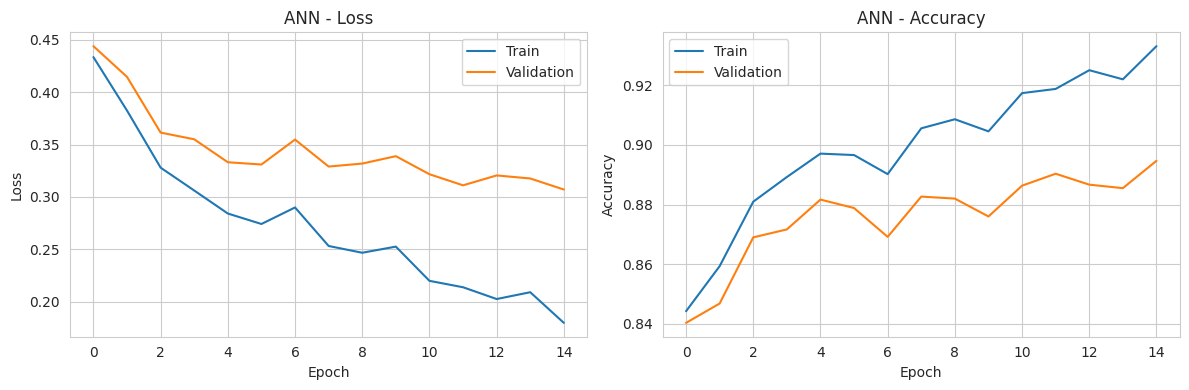

In [12]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()
    axes[1].plot(history["train_acc"], label="Train")
    axes[1].plot(history["val_acc"], label="Validation")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_ann, "ANN")

In [13]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.

def predict(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            out = model(xb.to(device))
            preds.append(out.argmax(dim=1).cpu())
    return torch.cat(preds).numpy()

ann_pred = predict(ann_model, test_loader)
print("Accuracy ANN (test):", round(accuracy_score(y_test, ann_pred), 4))

Accuracy ANN (test): 0.8961


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [14]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(42)
cnn_model = SimpleCNN().to(device)
print(cnn_model)
print("Jumlah parameter:", count_params(cnn_model))

# Perhitungan manual ukuran output: (W - K + 2P) / S + 1
# Input             : 1 x 28 x 28
# Conv1 (K=3,P=1,S=1): (28 - 3 + 2*1)/1 + 1 = 28  -> 32 x 28 x 28
# MaxPool (2)        : 28 / 2 = 14                -> 32 x 14 x 14
# Conv2 (K=3,P=1,S=1): (14 - 3 + 2*1)/1 + 1 = 14  -> 64 x 14 x 14
# MaxPool (2)        : 14 / 2 = 7                 -> 64 x 7 x 7
# Setelah Flatten    : 64 * 7 * 7 = 3136 -> input Linear pertama

# Pengecekan dengan tensor dummy
dummy = torch.zeros(1, 1, 28, 28).to(device)
x = dummy
with torch.no_grad():
    for layer in cnn_model.features:
        x = layer(x)
        print(f"{layer.__class__.__name__:10s} -> {tuple(x.shape)}")
print("Setelah Flatten:", x.flatten(1).shape[1])

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421642
Conv2d     -> (1, 32, 28, 28)
ReLU       -> (1, 32, 28, 28)
MaxPool2d  -> (1, 32, 14, 14)
Conv2d     -> (1, 64, 14, 14)
ReLU       -> (1, 64, 14, 14)
MaxPool2d  -> (1, 64, 7, 7)
Setelah Flatten: 3136


Epoch  1/15 | train loss 0.3971 acc 0.8546 | val loss 0.4065 acc 0.8545
Epoch  5/15 | train loss 0.2198 acc 0.9207 | val loss 0.2688 acc 0.9055
Epoch 10/15 | train loss 0.1418 acc 0.9491 | val loss 0.2335 acc 0.9163
Epoch 15/15 | train loss 0.0833 acc 0.9708 | val loss 0.2555 acc 0.9160


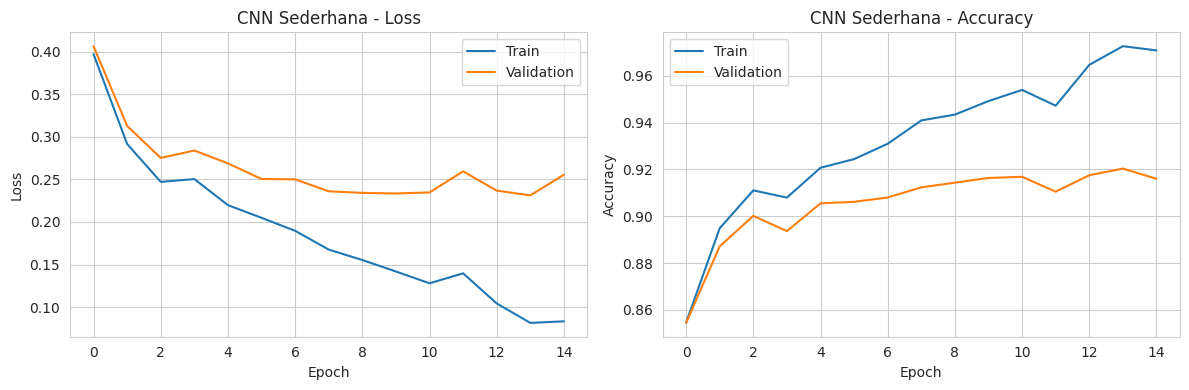

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=LR)
history_cnn = train_model(cnn_model, criterion, optimizer, EPOCHS)
plot_history(history_cnn, "CNN Sederhana")

In [16]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

cnn_pred = predict(cnn_model, test_loader)
print("Accuracy CNN Sederhana (test):", round(accuracy_score(y_test, cnn_pred), 4))

Accuracy CNN Sederhana (test): 0.9248


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.

class CNN_BN_Dropout(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(dropout),     # Dropout sebelum layer output
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(42)
cnn_bn_model = CNN_BN_Dropout().to(device)
print(cnn_bn_model)
print("Jumlah parameter:", count_params(cnn_bn_model))
# model.train() dan model.eval() sudah dipanggil di train_model() dan evaluate()/predict().

CNN_BN_Dropout(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421834


Epoch  1/15 | train loss 0.3080 acc 0.8839 | val loss 0.3299 acc 0.8768
Epoch  5/15 | train loss 0.1747 acc 0.9345 | val loss 0.2496 acc 0.9102
Epoch 10/15 | train loss 0.1149 acc 0.9585 | val loss 0.2310 acc 0.9175
Epoch 15/15 | train loss 0.0957 acc 0.9622 | val loss 0.2966 acc 0.9098


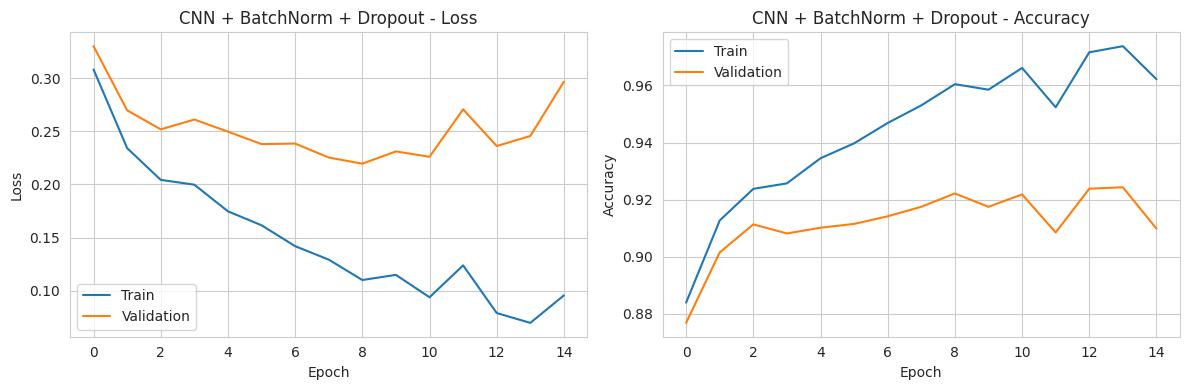

In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn_bn_model.parameters(), lr=LR)
history_cnn_bn = train_model(cnn_bn_model, criterion, optimizer, EPOCHS)
plot_history(history_cnn_bn, "CNN + BatchNorm + Dropout")
# Bandingkan selisih train vs validation dengan CNN sederhana (3.2).

In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

cnn_bn_pred = predict(cnn_bn_model, test_loader)
print("Accuracy CNN + BN + Dropout (test):", round(accuracy_score(y_test, cnn_bn_pred), 4))

Accuracy CNN + BN + Dropout (test): 0.9164


# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

models = {"ANN": ann_model, "CNN Sederhana": cnn_model, "CNN + BN + Dropout": cnn_bn_model}
preds = {"ANN": ann_pred, "CNN Sederhana": cnn_pred, "CNN + BN + Dropout": cnn_bn_pred}

rows = []
for name, pred in preds.items():
    rows.append({
        "Model": name,
        "Parameter": count_params(models[name]),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro"),
        "Recall (macro)": recall_score(y_test, pred, average="macro"),
        "F1 (macro)": f1_score(y_test, pred, average="macro"),
    })
metrics_df = pd.DataFrame(rows).set_index("Model")
display(metrics_df.round(4))

best_name = metrics_df["Accuracy"].idxmax()
best_model = models[best_name]
best_pred = preds[best_name]
print("Model terbaik (accuracy test):", best_name)

,Parameter,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,,
ANN,235146,0.8961,0.8984,0.8961,0.8968
CNN Sederhana,421642,0.9248,0.9266,0.9248,0.9252
CNN + BN + Dropout,421834,0.9164,0.9186,0.9164,0.9161


Model terbaik (accuracy test): CNN Sederhana


In [21]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

print(f"Classification report - {best_name}")
print(classification_report(y_test, best_pred, target_names=class_names, digits=4))

Classification report - CNN Sederhana
              precision    recall  f1-score   support

 T-shirt/top     0.8848    0.8760    0.8804      1000
     Trouser     0.9920    0.9920    0.9920      1000
    Pullover     0.9141    0.8510    0.8814      1000
       Dress     0.9512    0.8960    0.9228      1000
        Coat     0.8317    0.9240    0.8754      1000
      Sandal     0.9890    0.9860    0.9875      1000
       Shirt     0.7819    0.8140    0.7976      1000
     Sneaker     0.9686    0.9560    0.9623      1000
         Bag     0.9969    0.9780    0.9874      1000
  Ankle boot     0.9559    0.9750    0.9653      1000

    accuracy                         0.9248     10000
   macro avg     0.9266    0.9248    0.9252     10000
weighted avg     0.9266    0.9248    0.9252     10000



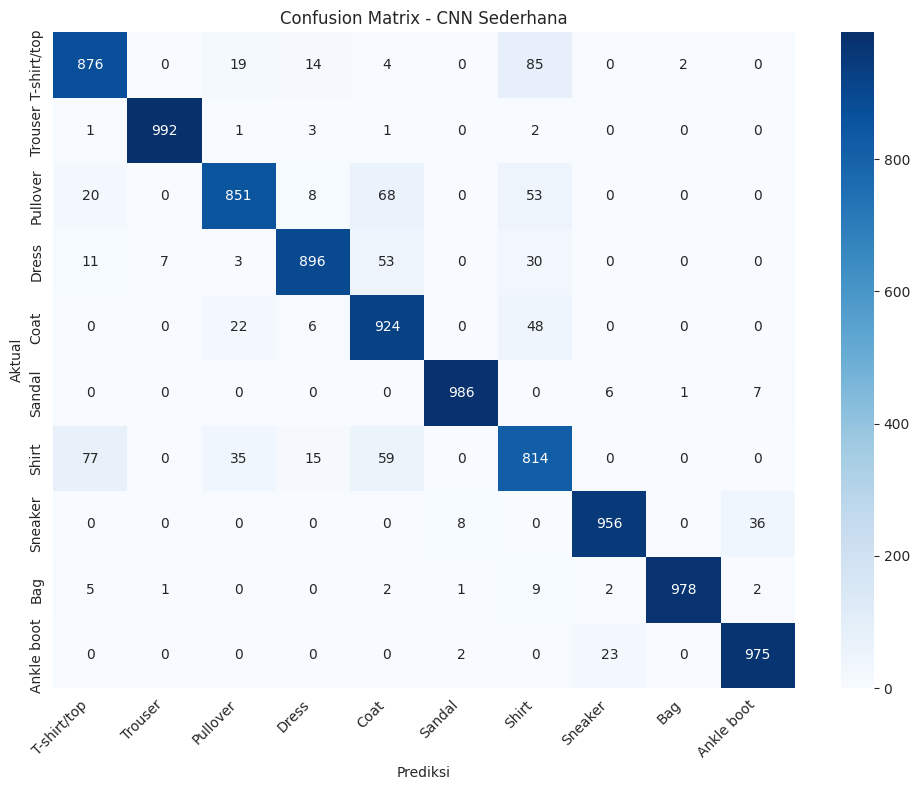

Lima kesalahan terbanyak (aktual -> prediksi):
  T-shirt/top -> Shirt: 85
  Shirt -> T-shirt/top: 77
  Pullover -> Coat: 68
  Shirt -> Coat: 59
  Dress -> Coat: 53


In [22]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi"); plt.ylabel("Aktual")
plt.title(f"Confusion Matrix - {best_name}")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Pasangan kelas yang paling sering tertukar (di luar diagonal)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1][:5], cm_off.shape))[0]
print("Lima kesalahan terbanyak (aktual -> prediksi):")
for a, p in top:
    print(f"  {class_names[a]} -> {class_names[p]}: {cm_off[a, p]}")

Jumlah salah klasifikasi: 752


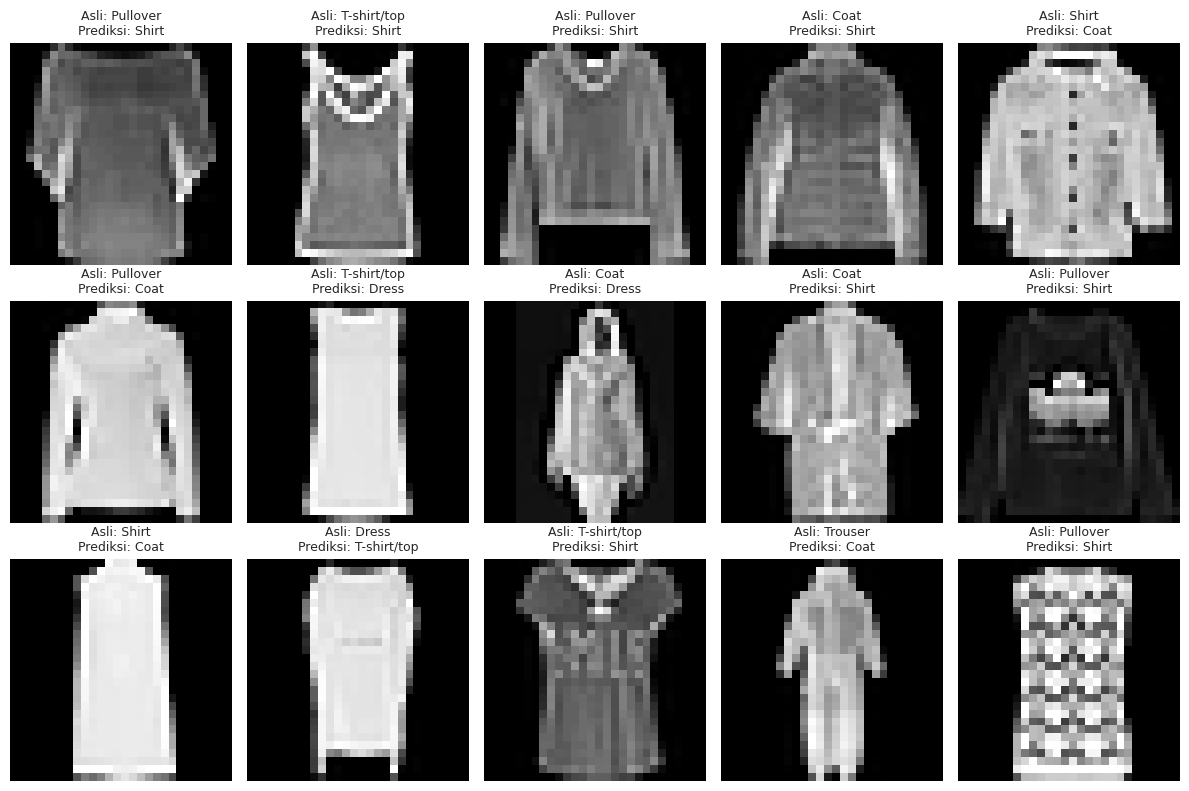

In [23]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

wrong_idx = np.where(best_pred != y_test)[0]
print("Jumlah salah klasifikasi:", len(wrong_idx))

sel = wrong_idx[:15]
fig, axes = plt.subplots(3, 5, figsize=(12, 8))
for ax, i in zip(axes.ravel(), sel):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Asli: {class_names[y_test[i]]}\nPrediksi: {class_names[best_pred[i]]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

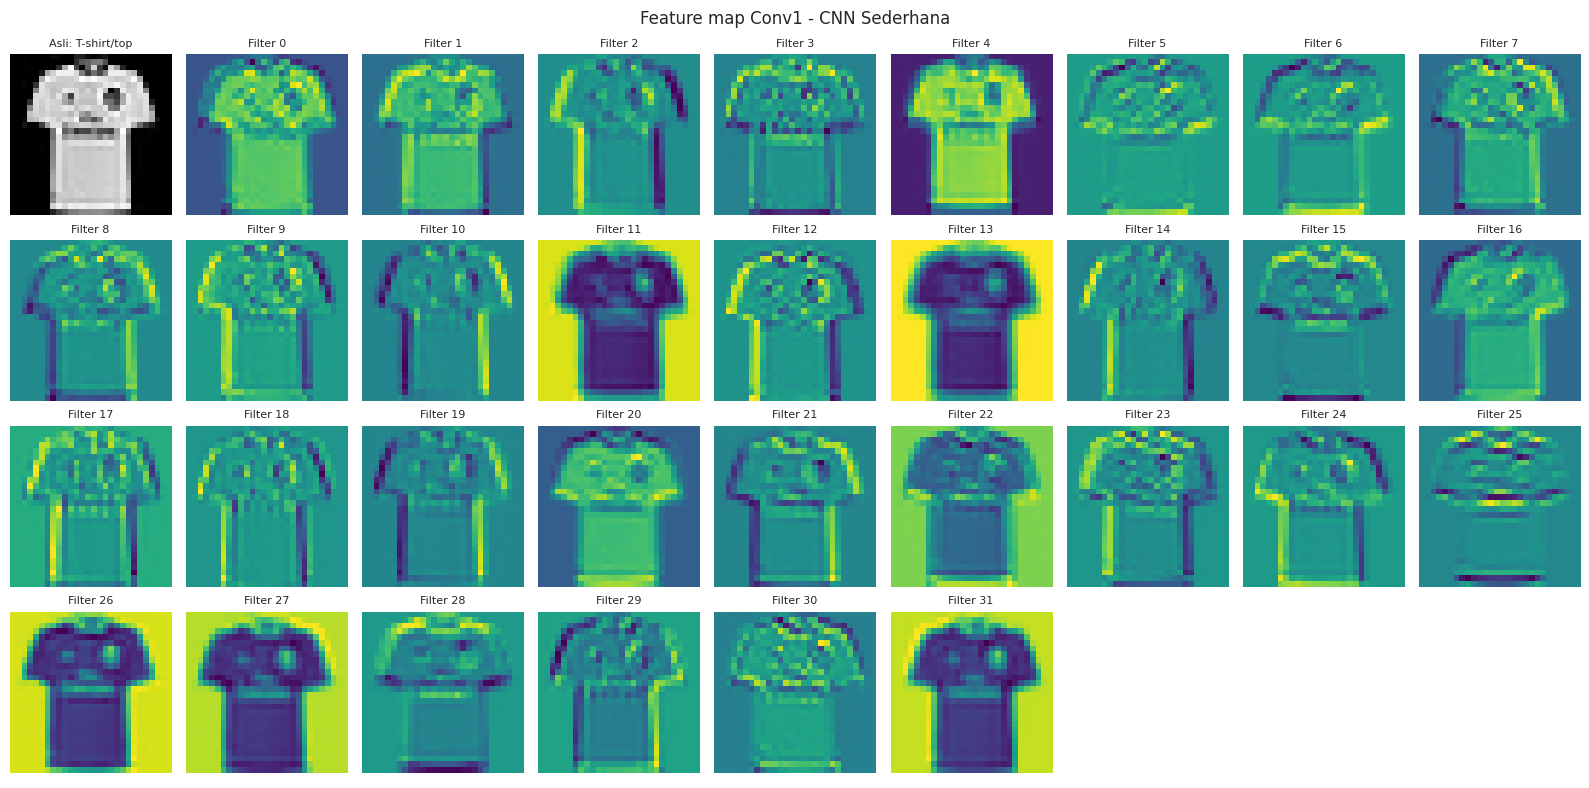

In [24]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?

# Feature map dari layer konvolusi pertama pada model CNN terbaik
cnn_candidates = {k: v for k, v in models.items() if k != "ANN"}
cnn_name = best_name if best_name in cnn_candidates else metrics_df.loc[list(cnn_candidates)]["Accuracy"].idxmax()
cnn_best = cnn_candidates[cnn_name]

cnn_best.eval()
x = X_test_t[0:1].to(device)          # (1, 1, 28, 28)
with torch.no_grad():
    fmap = cnn_best.features[0](x)    # output layer Conv2d pertama saja
fmap = fmap.detach().cpu().numpy()[0] # (32, 28, 28)

fig, axes = plt.subplots(4, 9, figsize=(16, 8))
axes[0, 0].imshow(X_test[0].reshape(28, 28), cmap="gray")
axes[0, 0].set_title(f"Asli: {class_names[y_test[0]]}", fontsize=8)
axes[0, 0].axis("off")
for k, ax in enumerate(axes.ravel()[1:]):
    if k < fmap.shape[0]:
        ax.imshow(fmap[k], cmap="viridis")
        ax.set_title(f"Filter {k}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Feature map Conv1 - {cnn_name}")
plt.tight_layout()
plt.show()
# Amati: sebagian filter menangkap tepi horizontal/vertikal, sebagian menangkap area terang/gelap.

In [25]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.

torch.save(best_model.state_dict(), "model.pth")
print(f"Bobot {best_name} disimpan ke model.pth")
# Simpan juga definisi class model (ANN / SimpleCNN / CNN_BN_Dropout) di atas
# karena dibutuhkan untuk memuat state_dict pada tugas Deployment.

Bobot CNN Sederhana disimpan ke model.pth


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

CNN sederhana memberi hasil terbaik dengan accuracy 0.9248 dan F1 macro 0.9252. CNN dengan Batch Normalization dan Dropout mencapai 0.9164 dan 0.9161, sedangkan ANN 0.8961 dan 0.8968. CNN sederhana unggul 2.9 poin atas ANN, atau 287 gambar lebih banyak yang benar dari 10.000 gambar test.

Jumlah parameter menjelaskan sebagian kecil dari selisih ini. ANN punya 235.146 parameter, CNN sederhana 421.642, dan CNN dengan BN dan Dropout 421.834 (192 parameter tambahan berasal dari Batch Normalization). Hampir semua parameter CNN berada di layer Linear(3136, 128), yaitu 401.536 parameter. Dua layer konvolusinya hanya berisi 18.816 parameter. Jadi keunggulan CNN datang dari cara memproses gambar: ANN meratakan gambar menjadi 784 angka sehingga piksel yang bertetangga diperlakukan sama seperti piksel yang berjauhan, sedangkan filter 3x3 pada CNN dipakai di semua posisi untuk membaca pola lokal, dan pooling membuat hasilnya lebih tahan terhadap pergeseran kecil.

Ketiga model overfit, dengan tingkat berbeda. Pada epoch 15, accuracy train ANN 0.9331 dan validation 0.8947 (gap 3.8 poin). CNN sederhana mencapai 0.9708 dan 0.9160 (gap 5.5 poin). Loss validation CNN sederhana paling rendah di sekitar epoch 10 (0.2335) lalu naik menjadi 0.2555, sementara loss train terus turun sampai 0.0833. Accuracy validation-nya mendatar di sekitar 0.91 sampai 0.92 sejak epoch 8, padahal accuracy train masih naik.

Batch Normalization mempercepat konvergensi. Di epoch 1, CNN dengan BN dan Dropout sudah mencapai accuracy validation 0.8768 dibanding 0.8545 pada CNN sederhana, dan loss train-nya 0.3080 dibanding 0.3971. Namun gap train dan validation hampir tidak berubah (0.9622 berbanding 0.9098, sekitar 5.2 poin), kurva validation lebih bergelombang, dan loss validation melonjak ke 0.2966 di epoch 15, lebih tinggi daripada CNN sederhana. Accuracy test-nya juga lebih rendah 0.84 poin. Pada setelan ini BN dan Dropout belum memberi manfaat untuk generalisasi. Kemungkinan penyebabnya Dropout 0.3 hanya dipasang satu kali di bagian classifier, padahal 401.536 parameter ada di layer tersebut. Perbedaan 0.84 poin juga berasal dari satu kali percobaan: accuracy validation CNN ini sempat mencapai sekitar 0.924 di epoch 13 sebelum turun ke 0.9098 di epoch 15, jadi hasil akhirnya cukup bergantung pada epoch tempat training berhenti.

Dari classification report CNN sederhana, kelas yang paling mudah adalah Trouser (F1 0.9920), Sandal (0.9875), dan Bag (0.9874), yang bentuknya khas. Kelas tersulit adalah Shirt (F1 0.7976, precision 0.7819, recall 0.8140), disusul Coat (0.8754), T-shirt/top (0.8804), dan Pullover (0.8814). Lima kesalahan terbanyak di confusion matrix adalah T-shirt/top diprediksi Shirt (85), Shirt diprediksi T-shirt/top (77), Pullover diprediksi Coat (68), Shirt diprediksi Coat (59), dan Dress diprediksi Coat (53). Semuanya pakaian bagian atas dengan siluet yang mirip. Pada resolusi 28x28, detail pembeda seperti kerah, kancing, dan panjang lengan nyaris hilang. Coat punya recall tinggi (0.9240) tetapi precision rendah (0.8317), artinya model cenderung memilih Coat ketika ragu. Dari 10.000 gambar test, 752 salah diklasifikasikan.

Feature map layer konvolusi pertama pada contoh gambar T-shirt menunjukkan pembagian tugas antar filter. Filter 0, 4, dan 20 menyala di bagian dalam pakaian yang terang. Filter 11, 13, 26, 27, dan 31 melakukan kebalikannya: aktif di latar hitam dan gelap di badan, sehingga membentuk siluet. Filter 2, 10, dan 14 menangkap tepi vertikal di sisi badan dan lengan, dan filter 25 menangkap tepi horizontal di bagian atas dan bawah. Layer pertama ini baru mengenali tepi dan area terang atau gelap. Bentuk pakaian yang lebih utuh baru dikenali di layer berikutnya.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

CNN sederhana adalah model terbaik pada eksperimen ini (accuracy 0.9248, F1 macro 0.9252), dan bobotnya disimpan sebagai model.pth untuk tugas Deployment. Konvolusi yang mempertahankan struktur spasial menaikkan accuracy 2.9 poin dibanding ANN, dengan bagian konvolusi hanya berisi 18.816 parameter. Batch Normalization membuat training lebih cepat, tetapi bersama Dropout 0.3 tidak memperbaiki accuracy test (0.9164) maupun gap train dan validation pada setelan ini. Kelas pakaian atas (Shirt, T-shirt/top, Pullover, Coat) tetap menjadi sumber kesalahan utama.

Perlu dicatat bahwa model.pth disimpan dari epoch 15, padahal loss validation CNN sederhana terendah di sekitar epoch 10. Setiap model juga hanya dilatih sekali, sehingga selisih kecil antara CNN sederhana dan CNN dengan BN dan Dropout belum tentu stabil.

Untuk eksperimen berikutnya, saya menyarankan menyimpan checkpoint dengan val loss terbaik atau memakai early stopping, menambah data augmentation (flip horizontal dan pergeseran kecil), memasang Dropout setelah tiap blok konvolusi atau menaikkan nilainya, menambah weight decay, dan memakai learning rate scheduler. Menambah satu blok konvolusi juga layak dicoba untuk membedakan kelas atasan yang mirip. Mengulang training dengan beberapa seed akan memastikan apakah BN dan Dropout benar-benar tidak membantu.